## Colab Hardware Information

In [1]:
# 1. GPU Information (Model name, VRAM, Driver version)
!nvidia-smi

# 2. CPU Model Name & Cores
!lscpu | grep -E 'Model name|Core\(s\) per socket|Thread\(s\) per core|CPU\(s\):'

# 3. System RAM (Memory)
!free -h --si | awk '/Mem:/{print "Total RAM: " $2}'

# 4. Storage Space
!df -h / | awk 'NR==2 {print "Total Disk: " $2 " (Used: " $3 ", Free: " $4 ")"}'

Wed Sep 16 17:24:05 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   56C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

# Loading the dataset

In [2]:
!mkdir -p data/full_dataset

!wget -P data/full_dataset/ https://storage.googleapis.com/gresearch/goemotions/data/full_dataset/goemotions_1.csv
!wget -P data/full_dataset/ https://storage.googleapis.com/gresearch/goemotions/data/full_dataset/goemotions_2.csv
!wget -P data/full_dataset/ https://storage.googleapis.com/gresearch/goemotions/data/full_dataset/goemotions_3.csv


--2026-09-16 17:24:06--  https://storage.googleapis.com/gresearch/goemotions/data/full_dataset/goemotions_1.csv
Resolving storage.googleapis.com (storage.googleapis.com)... 142.251.10.207, 142.251.12.207, 172.217.194.207, ...
Connecting to storage.googleapis.com (storage.googleapis.com)|142.251.10.207|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 14174600 (14M) [application/octet-stream]
Saving to: ‘data/full_dataset/goemotions_1.csv’

goemotions_1.csv    100%[===================>]  13.52M  7.43MB/s    in 1.8s    

2026-09-16 17:24:08 (7.43 MB/s) - ‘data/full_dataset/goemotions_1.csv’ saved [14174600/14174600]

--2026-09-16 17:24:08--  https://storage.googleapis.com/gresearch/goemotions/data/full_dataset/goemotions_2.csv
Resolving storage.googleapis.com (storage.googleapis.com)... 142.251.10.207, 142.251.12.207, 172.217.194.207, ...
Connecting to storage.googleapis.com (storage.googleapis.com)|142.251.10.207|:443... connected.
HTTP request sent, awaiting res

# Pre-processing libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
import os

from sklearn.feature_extraction.text import CountVectorizer


from collections import Counter

## Sectioning of data

In [4]:
path = "/content"  # default for Colab

data_path = os.path.join(path, "data/full_dataset")

# Load all parts safely
files = [
    "goemotions_1.csv",
    "goemotions_2.csv",
    "goemotions_3.csv"
]

dfs = []
for file in files:
    file_path = os.path.join(data_path, file)
    if os.path.exists(file_path):
        dfs.append(pd.read_csv(file_path))
    else:
        print(f"Missing file: {file_path}")



## Shape of datasets

In [5]:
for i in dfs:
  print(i.shape)
  print(i['id'].nunique())

(70000, 37)
43358
(70000, 37)
43448
(71225, 37)
43884


# Combining the three datasets, checking for duplicates and unique annotator ids

In [6]:
# Concatenate all 3 datasets into one
df = pd.concat(dfs, ignore_index=True)

print("Total combined rows:         ", len(df))
print("Total unique IDs across all: ", df['id'].nunique())
print("Exact duplicate rows count:  ", df.duplicated().sum())

Total combined rows:          211225
Total unique IDs across all:  58011
Exact duplicate rows count:   0


# Sample of the chosen *dataset* (dfs[2])

In [7]:
df.head()

,text,id,author,subreddit,link_id,parent_id,created_utc,rater_id,example_very_unclear,admiration,...,love,nervousness,optimism,pride,realization,relief,remorse,sadness,surprise,neutral
0,That game hurt.,eew5j0j,Brdd9,nrl,t3_ajis4z,t1_eew18eq,1.548381e+09,1,False,0,...,0,0,0,0,0,0,0,1,0,0
1,>sexuality shouldn’t be a grouping category I...,eemcysk,TheGreen888,unpopularopinion,t3_ai4q37,t3_ai4q37,1.548084e+09,37,True,0,...,0,0,0,0,0,0,0,0,0,0
2,"You do right, if you don't care then fuck 'em!",ed2mah1,Labalool,confessions,t3_abru74,t1_ed2m7g7,1.546428e+09,37,False,0,...,0,0,0,0,0,0,0,0,0,1
3,Man I love reddit.,eeibobj,MrsRobertshaw,facepalm,t3_ahulml,t3_ahulml,1.547965e+09,18,False,0,...,1,0,0,0,0,0,0,0,0,0
4,"[NAME] was nowhere near them, he was by the Fa...",eda6yn6,American_Fascist713,starwarsspeculation,t3_ackt2f,t1_eda65q2,1.546669e+09,2,False,0,...,0,0,0,0,0,0,0,0,0,1


## Checking null values

In [8]:
df.isnull().sum()

,0
text,0
id,0
author,0
subreddit,0
link_id,0
parent_id,0
created_utc,0
rater_id,0
example_very_unclear,0
admiration,0


## Checking Unique values

In [9]:
df.nunique()


,0
text,57732
id,58011
author,49178
subreddit,483
link_id,44897
parent_id,54924
created_utc,57257
rater_id,82
example_very_unclear,2
admiration,2


## Description of emotion columns

In [10]:
emotion_cols = [
'admiration','amusement','anger','annoyance','approval','caring',
'confusion','curiosity','desire','disappointment','disapproval',
'disgust','embarrassment','excitement','fear','gratitude','grief',
'joy','love','nervousness','optimism','pride','realization','relief',
'remorse','sadness','surprise','neutral'
]

## Sorting the emotions in accordance to the frequencies in Descending order

In [11]:
emotion_counts = df[emotion_cols].sum().sort_values(ascending=False)


## Histogram of Emotion Frequency in GoEmotions Dataset

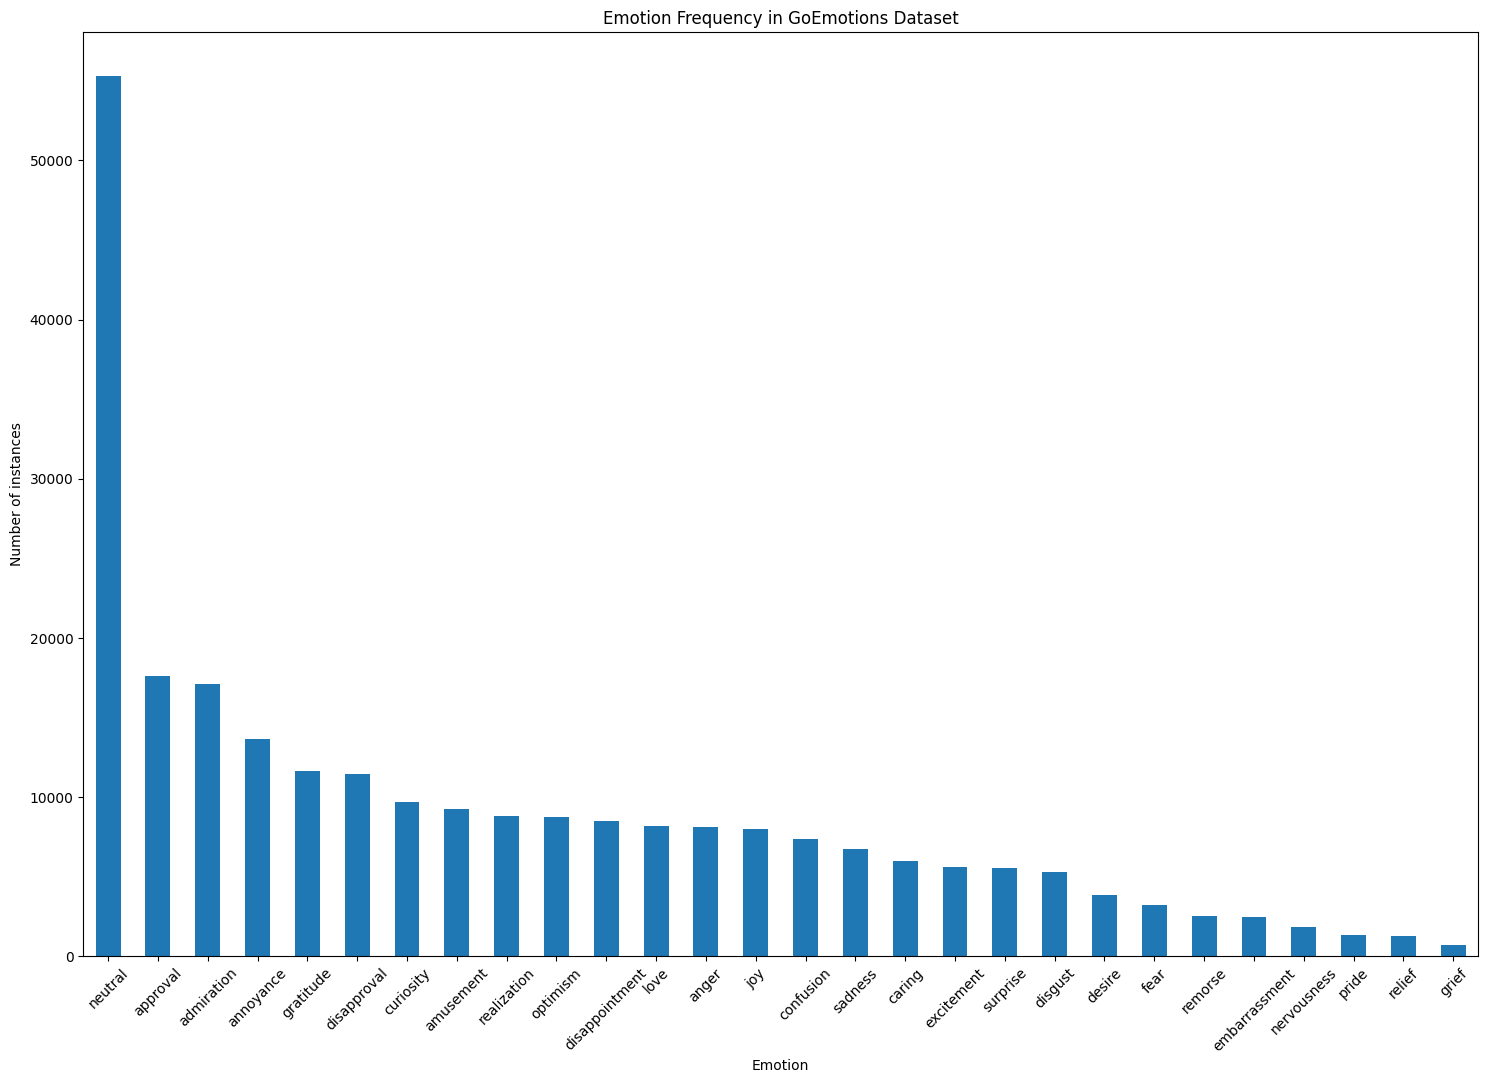

In [12]:
plt.figure(figsize=(18,12))
emotion_counts.plot(kind='bar')
plt.title("Emotion Frequency in GoEmotions Dataset")
plt.ylabel("Number of instances")
plt.xlabel("Emotion")
plt.xticks(rotation=45)
plt.show()

# Top Words

## Performing TF-IDF

In [13]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(max_features=5000, stop_words='english')
X = vectorizer.fit_transform(df['text'])

words = vectorizer.get_feature_names_out()


## Defining the function for getting top words

In [14]:
def get_top_words(emotion, top_n=10):
    mask = df[emotion] == 1
    emotion_X = vectorizer.transform(df[mask]['text'])

    scores = emotion_X.mean(axis=0).A1

    emotion_df = pd.DataFrame({
        'word': words,
        'score': scores
    }).sort_values('score', ascending=False)

    return emotion_df.head(top_n)

## Storing top words for each emotion

In [15]:
results = {}

for emotion in emotion_cols:
    results[emotion] = get_top_words(emotion, top_n=8)

## Displaying the top 8 words associated for each emotion

In [16]:
for emotion, df_top in results.items():
    print("\n", emotion.upper())
    print(df_top)


 ADMIRATION
         word     score
1957     good  0.045978
1990    great  0.044278
384   awesome  0.026733
214   amazing  0.023792
2614     like  0.021926
2995     nice  0.020706
2686     love  0.020635
491      best  0.018752

 AMUSEMENT
       word     score
2660    lol  0.128152
2034   haha  0.039930
1874  funny  0.035699
1868    fun  0.025366
2647   lmao  0.023474
2614   like  0.020246
2458   just  0.019316
2442   joke  0.017022

 ANGER
         word     score
1862     fuck  0.046738
2082     hate  0.036247
1865  fucking  0.028612
2458     just  0.019614
1388      don  0.019394
3212   people  0.016581
2614     like  0.015132
1176     damn  0.015103

 ANNOYANCE
         word     score
2458     just  0.020429
1388      don  0.019790
2614     like  0.019187
3212   people  0.016961
1862     fuck  0.013228
1176     damn  0.013135
1865  fucking  0.012231
4287   stupid  0.011736

 APPROVAL
       word     score
2614   like  0.022217
2458   just  0.019470
1957   good  0.017410
175   agre

In [17]:
summary_rows = []

for emotion, df_top in results.items():
    words = ", ".join(df_top["word"].head(5).values)

    summary_rows.append({
        "emotion": emotion,
        "top_words": words
    })

summary_df = pd.DataFrame(summary_rows)


In [18]:
from IPython.display import display

display(summary_df)


,emotion,top_words
0,admiration,"good, great, awesome, amazing, like"
1,amusement,"lol, haha, funny, fun, lmao"
2,anger,"fuck, hate, fucking, just, don"
3,annoyance,"just, don, like, people, fuck"
4,approval,"like, just, good, agree, right"
5,caring,"don, good, just, luck, better"
6,confusion,"don, know, sure, think, like"
7,curiosity,"did, curious, like, just, know"
8,desire,"wish, want, hope, like, need"
9,disappointment,"bad, just, like, don, really"


## We compare emotions to each other using a heatmap without taking into account text

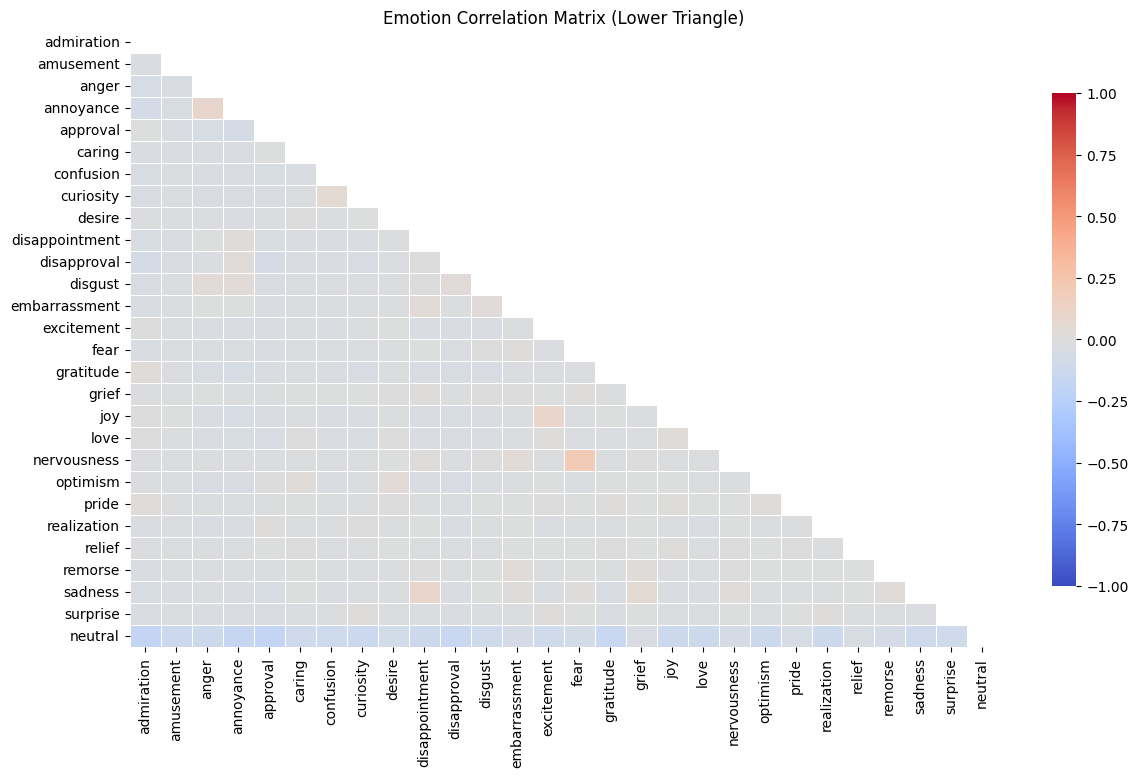

In [19]:
corr= df[emotion_cols].corr()
# mask upper triangle
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(14,8))

sns.heatmap(
    corr,
    mask=mask,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8}
)

plt.title("Emotion Correlation Matrix (Lower Triangle)")
plt.show()

Mean Word Count: 13.00
Median Word Count: 13.00
99th Percentile Word Count: 27.00
Max Word Count: 33


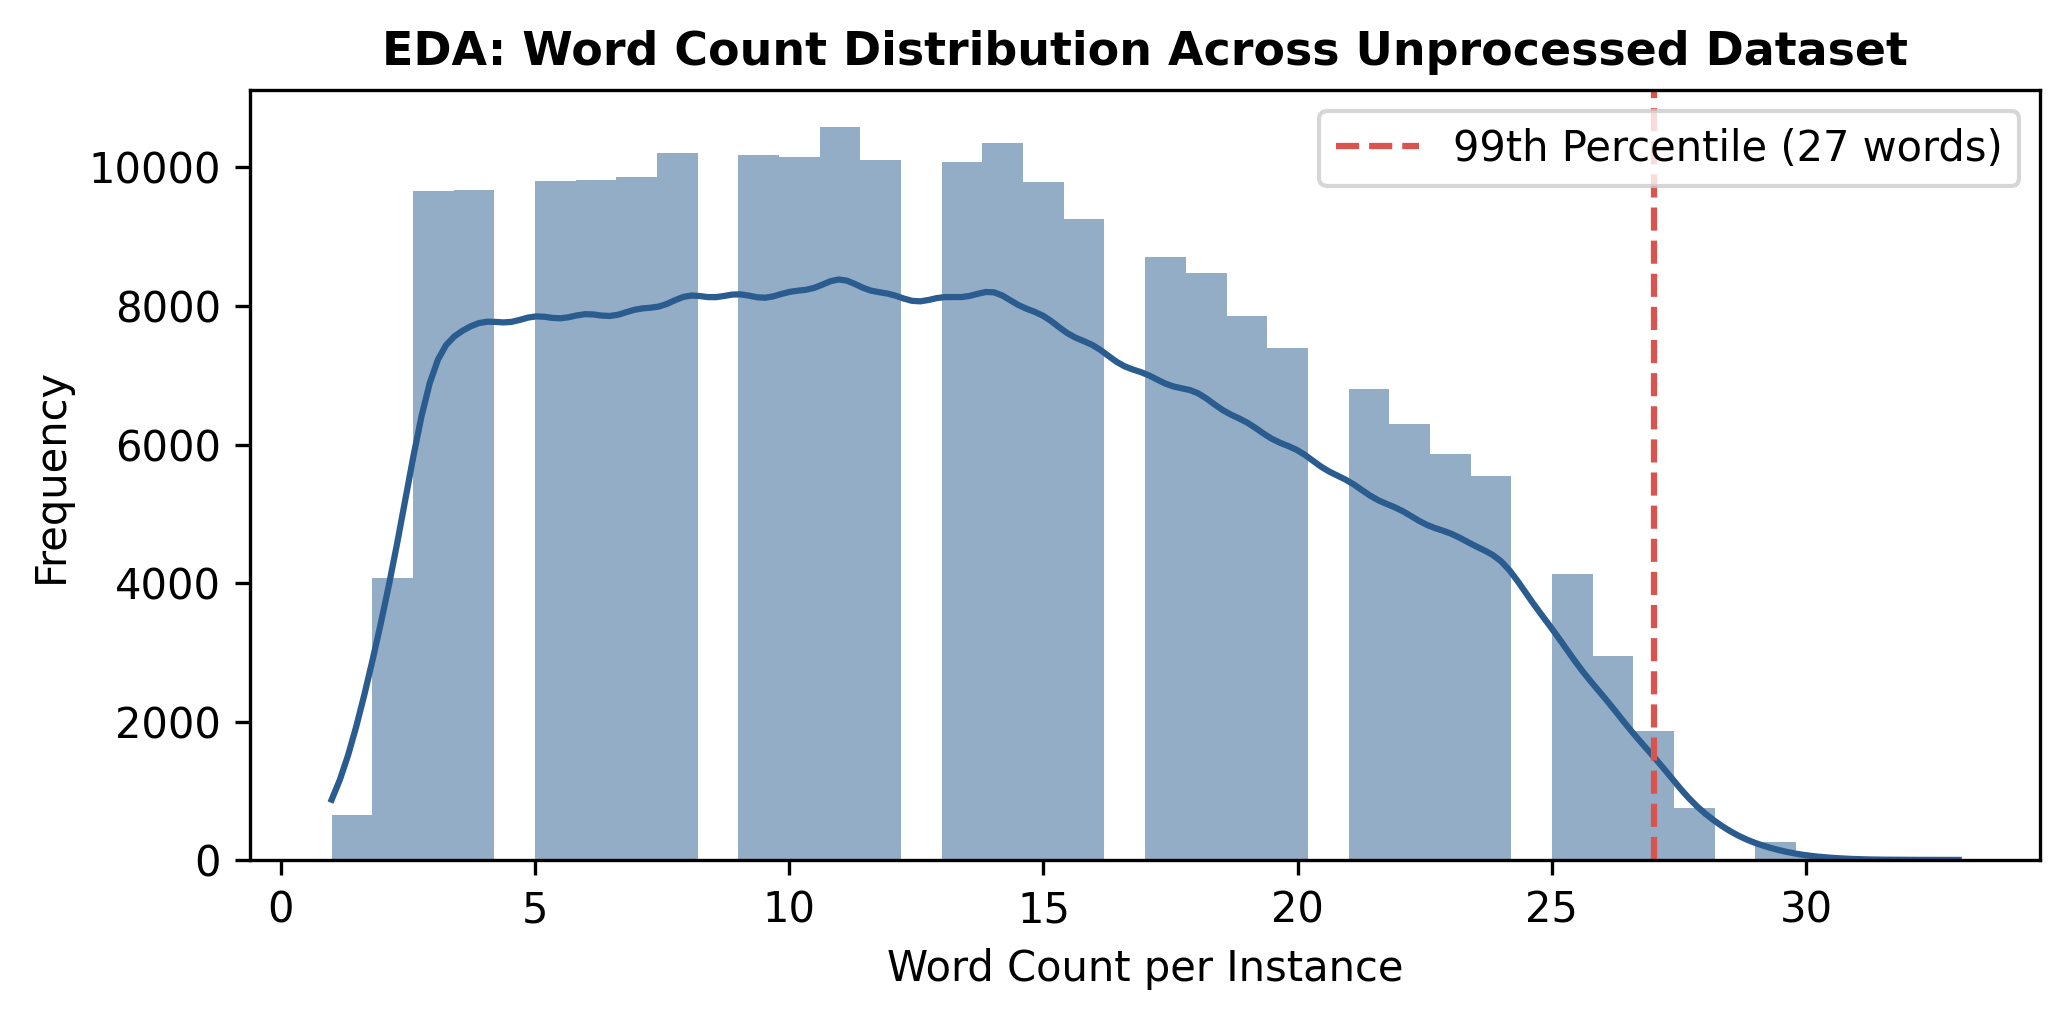

In [20]:
# Compute raw word count distribution
word_counts = df['text'].astype(str).apply(lambda x: len(x.split()))

# Calculate descriptive statistics
mean_words = word_counts.mean()
median_words = word_counts.median()
p99_words = np.percentile(word_counts, 99)
max_words = word_counts.max()

print(f"Mean Word Count: {mean_words:.2f}")
print(f"Median Word Count: {median_words:.2f}")
print(f"99th Percentile Word Count: {p99_words:.2f}")
print(f"Max Word Count: {max_words}")

# EDA Plot for report
plt.figure(figsize=(7, 3.5), dpi=300)
sns.histplot(word_counts, bins=40, kde=True, color='#2b5c8f', edgecolor='none')
plt.axvline(x=p99_words, color='#d9534f', linestyle='--', label=f'99th Percentile ({p99_words:.0f} words)')
plt.title('EDA: Word Count Distribution Across Unprocessed Dataset', fontsize=11, fontweight='bold')
plt.xlabel('Word Count per Instance')
plt.ylabel('Frequency')
plt.legend()
plt.tight_layout()
plt.show()

# **DF1**

## Ensuring each row of text has only one emotion label by labelling the row with the emotion that most annotators (more than 50%) labelled the text with

## If the winning emotion is neutral and other annotators have labelled the text with other emotions, it is replaced with the second highest emotion.

## If the text with only been labelled as neutral, it will be labelled as neutral.

In [21]:
def resolve_group(group):
    n = len(group)
    threshold = n / 2
    counts = group[emotion_cols].sum()          # raw vote counts, 27 real emotions
    result = (counts > threshold).astype(int)   # majority pass as before
    result['neutral'] = 0

    if result.sum() == 0:
        # no real emotion reached majority
        if counts.sum() == 0:
            # nobody flagged any real emotion at all -> pure neutral, keep it
            result['neutral'] = 1
        else:
            # some annotators DID flag real emotions, just not enough for
            # majority -> neutral doesn't win by default, top-voted emotion does
            top_emotion = counts.idxmax()
            result[top_emotion] = 1

    return result

df_blanked = df.copy()

agg = df_blanked.groupby('text').apply(resolve_group)
meta = df_blanked.groupby('text', as_index=False).agg(
    {c: 'first' for c in ['id', 'author', 'subreddit', 'link_id',
                           'parent_id', 'created_utc', 'example_very_unclear']}
)
df1 = meta.merge(agg.reset_index(), on='text')

print(df1.shape)

/tmp/ipykernel_860/3075120639.py:23: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  agg = df_blanked.groupby('text').apply(resolve_group)


(57732, 36)


# Checking columns within the processed dataset

In [22]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 57732 entries, 0 to 57731
Data columns (total 36 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   text                  57732 non-null  object 
 1   id                    57732 non-null  object 
 2   author                57732 non-null  object 
 3   subreddit             57732 non-null  object 
 4   link_id               57732 non-null  object 
 5   parent_id             57732 non-null  object 
 6   created_utc           57732 non-null  float64
 7   example_very_unclear  57732 non-null  bool   
 8   admiration            57732 non-null  int64  
 9   amusement             57732 non-null  int64  
 10  anger                 57732 non-null  int64  
 11  annoyance             57732 non-null  int64  
 12  approval              57732 non-null  int64  
 13  caring                57732 non-null  int64  
 14  confusion             57732 non-null  int64  
 15  curiosity          

In [23]:
df1.head()

,text,id,author,subreddit,link_id,parent_id,created_utc,example_very_unclear,admiration,amusement,...,love,nervousness,optimism,pride,realization,relief,remorse,sadness,surprise,neutral
0,"""If you don't wear BROWN AND ORANGE...YOU DON...",ee3fxil,pj7140,Browns,t3_afy4f0,t3_afy4f0,1.547522e+09,False,0,0,...,0,0,0,0,0,0,0,0,0,0
1,"""What do Scottish people look like?"" How I wo...",ee7cu0z,Cheezeburger_Picnic,Scotland,t3_agmpx9,t3_agmpx9,1.547658e+09,False,0,0,...,1,0,0,0,0,0,0,0,0,0
2,"### A surprise, to be sure, but a welcome one",edglo8q,GPFlopi,youseeingthisshit,t3_ad1hnf,t3_ad1hnf,1.546855e+09,False,0,0,...,0,0,0,0,0,0,0,0,1,0
3,"'*Pray*, v. To ask that the laws of the unive...",edcjn6t,DarrenFromFinance,exchristian,t3_ad0jpf,t3_ad0jpf,1.546740e+09,False,0,0,...,0,0,0,0,0,0,0,0,0,1
4,">it'll get invaded by tankie, unfortunately. ...",eevxqzo,BarrelMaker69,BreadTube,t3_ajbca2,t1_eevv6db,1.548375e+09,False,0,0,...,0,0,0,0,0,0,0,0,0,1


## Displaying emotion frequency after aggregation

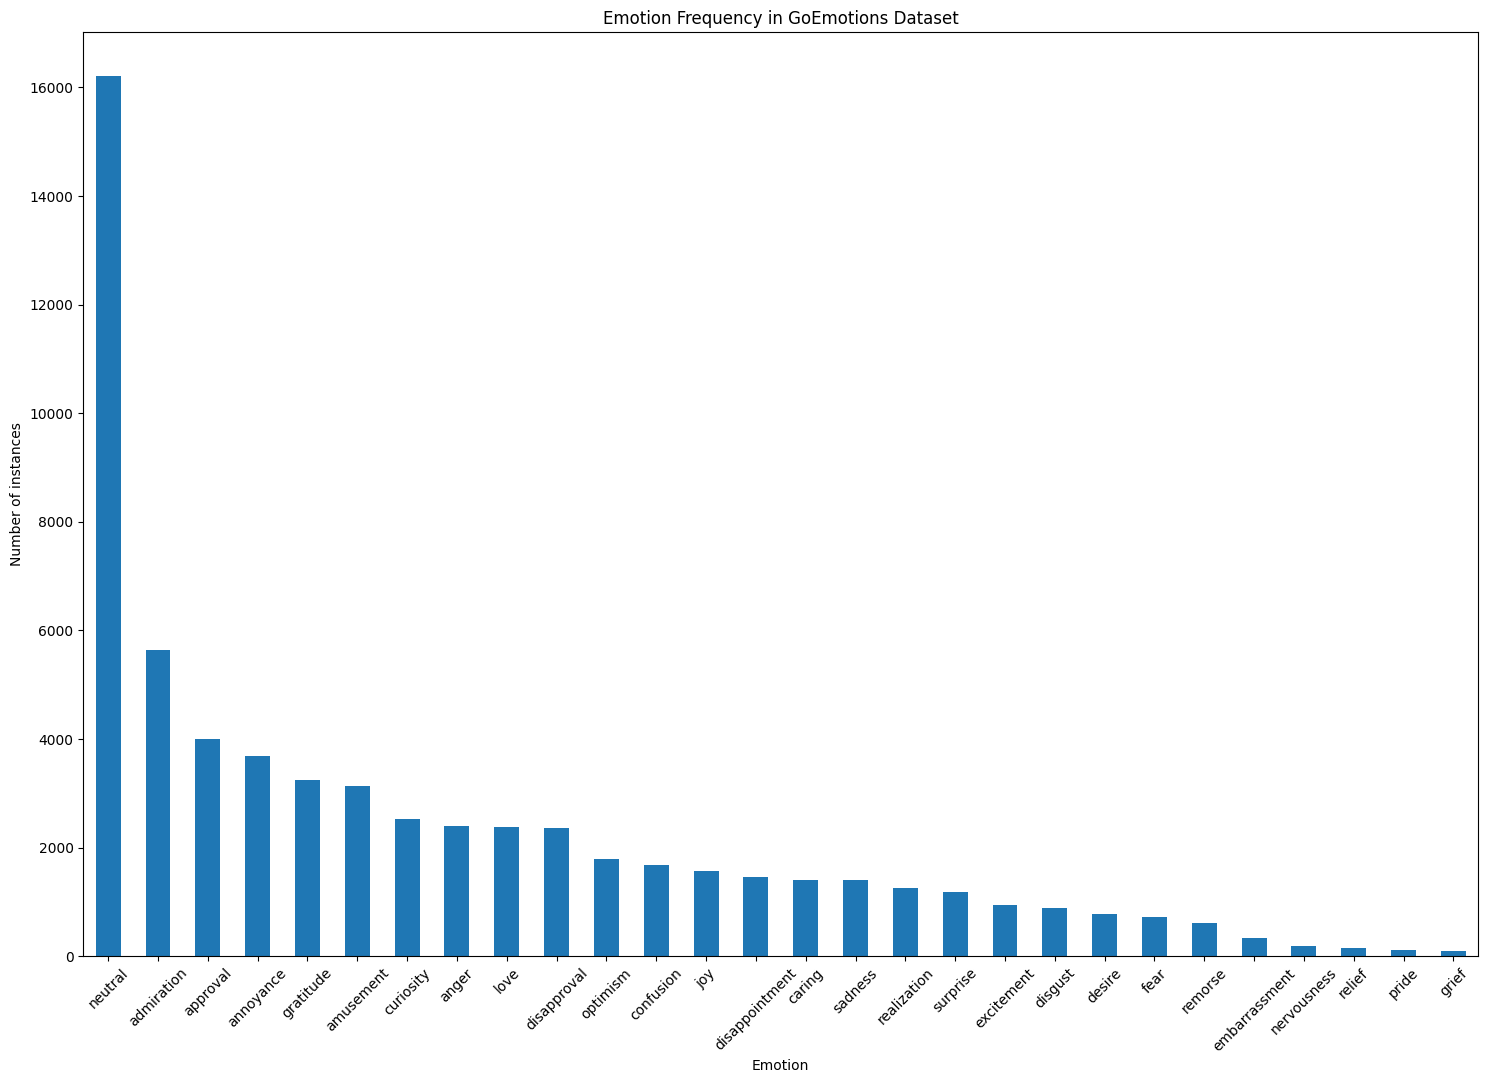

In [24]:
emotion_counts = df1[emotion_cols].sum().sort_values(ascending=False)

plt.figure(figsize=(18,12))
emotion_counts.plot(kind='bar')
plt.title("Emotion Frequency in GoEmotions Dataset")
plt.ylabel("Number of instances")
plt.xlabel("Emotion")
plt.xticks(rotation=45)
plt.show()

# Displaying columns within the processed dataset

In [25]:
df1.columns

Index(['text', 'id', 'author', 'subreddit', 'link_id', 'parent_id',
       'created_utc', 'example_very_unclear', 'admiration', 'amusement',
       'anger', 'annoyance', 'approval', 'caring', 'confusion', 'curiosity',
       'desire', 'disappointment', 'disapproval', 'disgust', 'embarrassment',
       'excitement', 'fear', 'gratitude', 'grief', 'joy', 'love',
       'nervousness', 'optimism', 'pride', 'realization', 'relief', 'remorse',
       'sadness', 'surprise', 'neutral'],
      dtype='object')

# Displaying the number of emotions the rows of data have been annotated with

In [26]:
df1["num_emotions"] = df1[emotion_cols].sum(axis=1)

df1["num_emotions"].value_counts().sort_index()


,count
num_emotions,
1,53653
2,3813
3,262
4,4


## removing rows with no labels and more than one label of emotion AND STORING IT INTO df2

In [27]:
df2 = df1[df1[emotion_cols].sum(axis=1) == 1]
df2.shape

(53653, 37)

# Only including rows with column "example_very_unclear" as false AND STORING IT INTO df_fin

# Displaying the shape of df_fin

In [28]:
df_fin = df2[df2["example_very_unclear"] == False]
df_fin.shape

(52814, 37)

# Displaying the columns of df_fin

In [29]:
df_fin.columns

Index(['text', 'id', 'author', 'subreddit', 'link_id', 'parent_id',
       'created_utc', 'example_very_unclear', 'admiration', 'amusement',
       'anger', 'annoyance', 'approval', 'caring', 'confusion', 'curiosity',
       'desire', 'disappointment', 'disapproval', 'disgust', 'embarrassment',
       'excitement', 'fear', 'gratitude', 'grief', 'joy', 'love',
       'nervousness', 'optimism', 'pride', 'realization', 'relief', 'remorse',
       'sadness', 'surprise', 'neutral', 'num_emotions'],
      dtype='object')

# Objective 2 : Creating an optimized 7 emotion Scheme based purely on GoEmotions

### libraries needed for section 2

In [30]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_distances, cosine_similarity
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform


## we remove row with neutral emotions as they are difficult to ascertain and understand.

In [31]:
df_active = df_fin[df_fin['neutral'] == 0].copy()
print("shape of df_active : " + str(df_active.shape))
print( "removed : " + str(df_fin.shape[0] - df_active.shape[0]) + " rows" )

shape of df_active : (36908, 37)
removed : 15906 rows


## Displaying new distribution of emotions

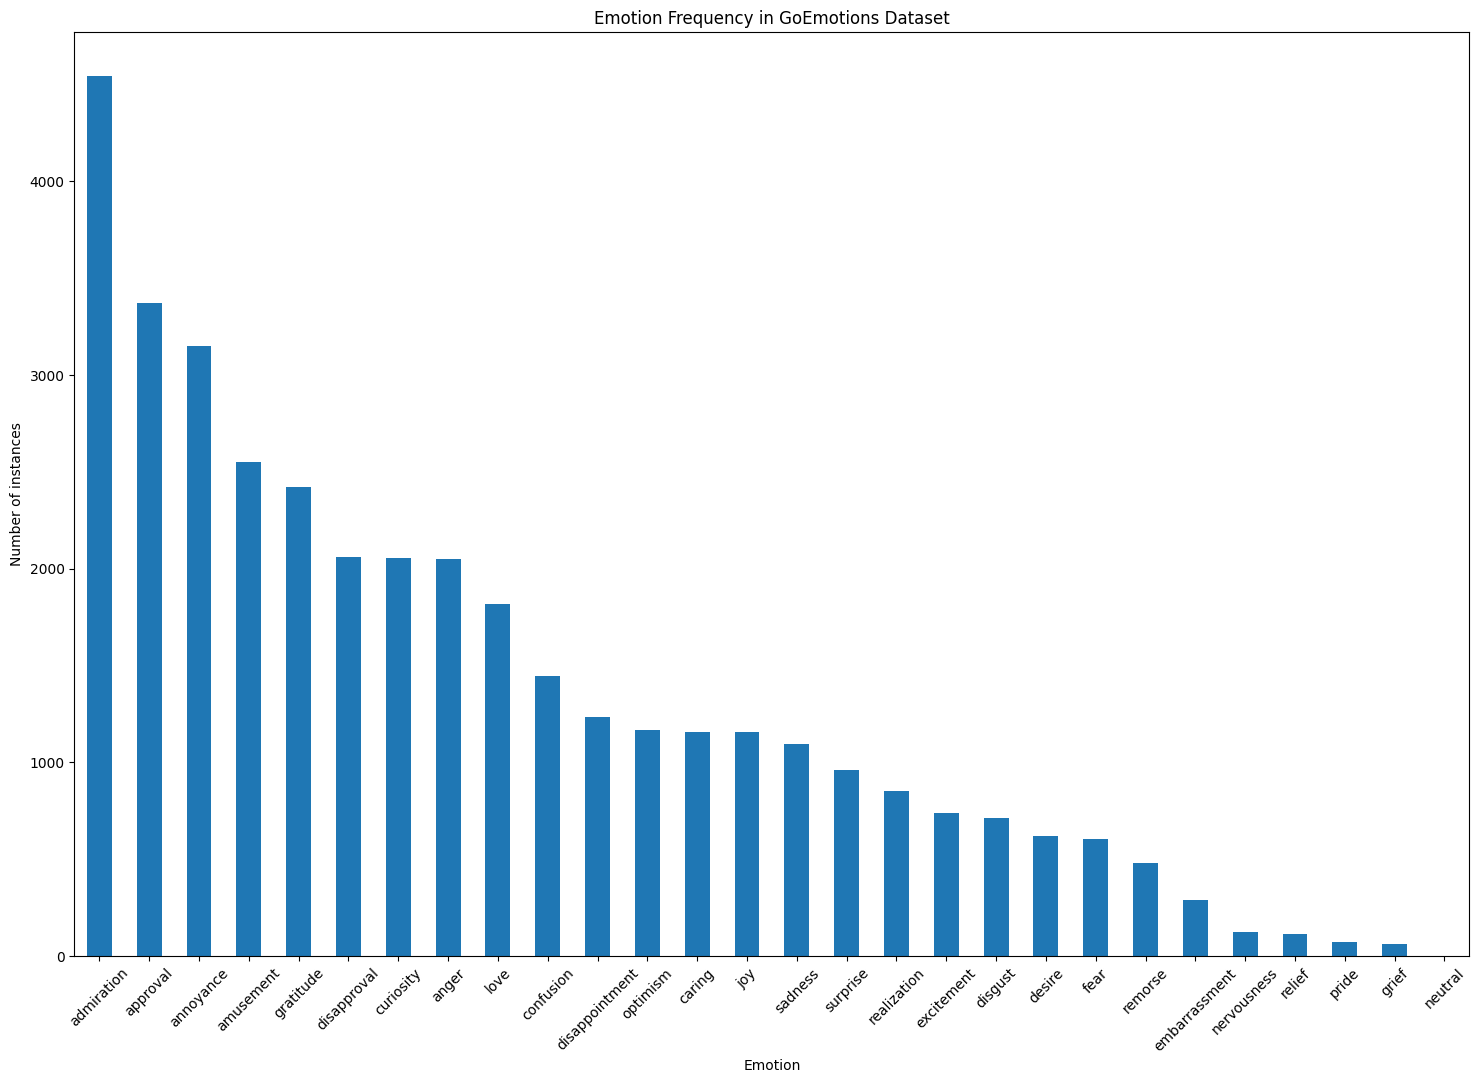

In [32]:
emotion_counts = df_active[emotion_cols].sum().sort_values(ascending=False)
plt.figure(figsize=(18,12))
emotion_counts.plot(kind='bar')
plt.title("Emotion Frequency in GoEmotions Dataset")
plt.ylabel("Number of instances")
plt.xlabel("Emotion")
plt.xticks(rotation=45)
plt.show()

## The goemotions names we are using

In [33]:
goemotions_27= ['admiration',
       'amusement', 'anger', 'annoyance', 'approval', 'caring', 'confusion',
       'curiosity', 'desire', 'disappointment', 'disapproval', 'disgust',
       'embarrassment', 'excitement', 'fear', 'gratitude', 'grief', 'joy',
       'love', 'nervousness', 'optimism', 'pride', 'realization', 'relief',
       'remorse', 'sadness', 'surprise']

### Vectorizing emotions and using hiearchical clustering to determine 6 new emotions.

### df_custom IS THE NEW EMOTION CLASSIFICATION SCHEME ADJUSTED DATAFRAME

<Figure size 1200x1000 with 0 Axes>

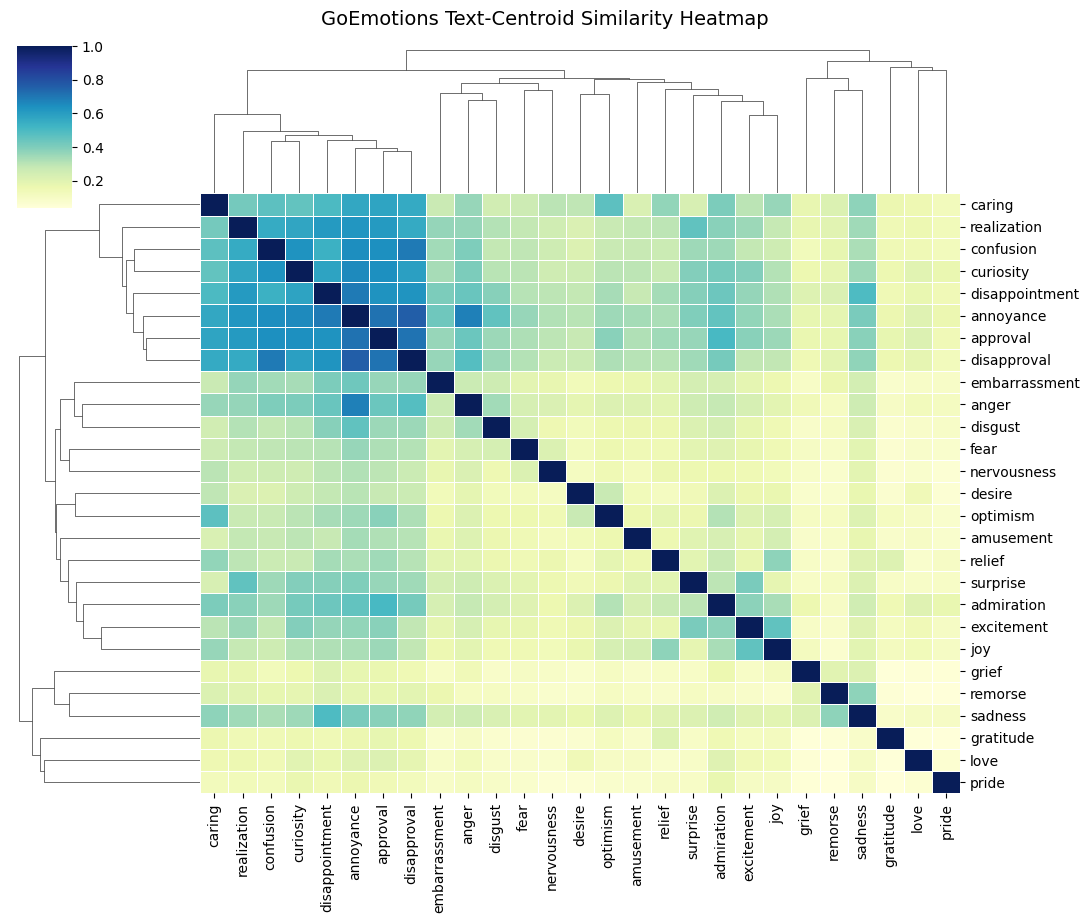


=== Text-Grounded 6-Cluster Scheme ===
Cluster_4 (9 emotions): ['admiration', 'amusement', 'caring', 'desire', 'excitement', 'joy', 'optimism', 'relief', 'surprise']
Cluster_2 (5 emotions): ['anger', 'disgust', 'embarrassment', 'fear', 'nervousness']
Cluster_1 (7 emotions): ['annoyance', 'approval', 'confusion', 'curiosity', 'disappointment', 'disapproval', 'realization']
Cluster_6 (1 emotions): ['gratitude']
Cluster_3 (3 emotions): ['grief', 'remorse', 'sadness']
Cluster_5 (2 emotions): ['love', 'pride']

=== Representative Emotion per Cluster Summary ===
          Representative Cluster_Size Count  \
Cluster_4     admiration            9  4542   
Cluster_2          anger            5  2051   
Cluster_1       approval            7  3371   
Cluster_6      gratitude            1  2420   
Cluster_3        sadness            3  1096   
Cluster_5           love            2  1819   

                                                All_Emotions  
Cluster_4  [admiration, amusement, caring, 

In [34]:
# 1. Vectorize the text using TF-IDF (removing English stop words)
tfidf = TfidfVectorizer(
    stop_words='english',
    max_df=0.5,
    min_df=3,
    ngram_range=(1, 2)
)
X_tfidf = tfidf.fit_transform(df_active['text'])

# 2. Compute the Mean Centroid Vector for each of the 27 emotions
# (Matrix multiplication: [27 x N] @ [N x Features] -> [27 x Features])
label_matrix = df_active[goemotions_27].values.T  # Shape: (27, N)
label_counts = label_matrix.sum(axis=1, keepdims=True)  # Shape: (27, 1)

# Average feature representation per emotion
emotion_centroids = (label_matrix @ X_tfidf) / label_counts

# 3. Compute Cosine Distance Matrix across the text-based emotion centroids
dist_matrix = cosine_distances(emotion_centroids)
similarity_matrix = 1 - dist_matrix

df_text_sim = pd.DataFrame(similarity_matrix, index=goemotions_27, columns=goemotions_27)

# 4. Plot Text-Grounded Heatmap
plt.figure(figsize=(12, 10))
g = sns.clustermap(
    df_text_sim,
    cmap="YlGnBu",
    linewidths=.5,
    figsize=(11, 9)
)
g.fig.suptitle("GoEmotions Text-Centroid Similarity Heatmap", y=1.02, fontsize=14)
plt.show()

# 5. Extract 6 Macro-Clusters via Hierarchical Clustering (Ward's Linkage)
# Note: Ward requires Euclidean space; sqrt(2 * CosineDistance) maps unit vectors to Euclidean space.
euclidean_from_cosine = np.sqrt(2 * np.clip(dist_matrix, 0, None))
condensed_dist = squareform(euclidean_from_cosine)

Z = linkage(condensed_dist, method='ward')
cluster_assignments = fcluster(Z, t=6, criterion='maxclust')

# Map emotions to custom cluster IDs
text_hac_clusters = {}
for emotion, cluster_id in zip(goemotions_27, cluster_assignments):
    text_hac_clusters.setdefault(f"Cluster_{cluster_id}", []).append(emotion)

print("\n=== Text-Grounded 6-Cluster Scheme ===")
for cluster_name, members in text_hac_clusters.items():
    print(f"{cluster_name} ({len(members)} emotions): {members}")

# 6. Determine Representative (Most Frequent) Emotion for Each Cluster
cluster_representatives = {}
renamed_clusters = {}

for cluster_id, emotions in text_hac_clusters.items():
    # Sum counts of each emotion in the cluster to find the dominant one
    counts = df_active[emotions].sum()
    rep_label = counts.idxmax()

    cluster_representatives[cluster_id] = {
        'Representative': rep_label,
        'Count': counts.max(),
        'Cluster_Size': len(emotions),
        'All_Emotions': emotions
    }
    renamed_clusters[cluster_id] = rep_label

df_rep_summary = pd.DataFrame(cluster_representatives).T
print("\n=== Representative Emotion per Cluster Summary ===")
print(df_rep_summary[['Representative', 'Cluster_Size', 'Count', 'All_Emotions']])

# 7. Build final df_custom DataFrame with Representative Emotion Column Names
df_custom = df_active[['text']].copy()

for cluster_id, child_emotions in text_hac_clusters.items():
    rep_name = renamed_clusters[cluster_id]
    df_custom[rep_name] = df_active[child_emotions].max(axis=1)

# Drop rows with 0 active tags across the 6 macro-classes
custom_label_cols = list(renamed_clusters.values())
df_custom = df_custom[df_custom[custom_label_cols].sum(axis=1) > 0].reset_index(drop=True)

print("\n--- Final Active Sample Count per Representative Class ---")
print(df_custom[custom_label_cols].sum().sort_values(ascending=False))

## New emotion classification scheme dataframe

In [35]:
df_custom.head()

,text,admiration,anger,approval,gratitude,sadness,love
0,"""If you don't wear BROWN AND ORANGE...YOU DON...",0,0,1,0,0,0
1,"### A surprise, to be sure, but a welcome one",1,0,0,0,0,0
2,And not all children's hospitals need the sam...,0,0,1,0,0,0
3,"Best number! [NAME], [NAME], [NAME]",1,0,0,0,0,0
4,Calm down and relax are the worst things to s...,0,0,1,0,0,0


# Objective 3 : Training BERT, ELECTRA and ROBERTA models based on Ekman's scheme, new 5-emotion, 6-emotion and 7-emotion scheme.

### Libraries required for section 3


In [36]:
import torch
import torch.nn as nn

from sklearn.utils.class_weight import compute_class_weight
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from sklearn.metrics import confusion_matrix

from transformers import (
    AutoConfig,
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
    EarlyStoppingCallback
)

from datasets import Dataset


from scipy.stats import spearmanr
from IPython.display import display_html

## Ekman's conversion

In [37]:
# Standard GoEmotions -> Ekman Mapping Dictionary
ekman_mapping = {
    'anger': ['anger', 'annoyance', 'disapproval'],
    'disgust': ['disgust'],
    'fear': ['fear', 'nervousness'],
    'joy': ['admiration', 'amusement', 'approval', 'caring', 'desire',
            'excitement', 'gratitude', 'joy', 'love', 'optimism', 'pride', 'relief'],
    'sadness': ['disappointment', 'embarrassment', 'grief', 'remorse', 'sadness'],
    'surprise': ['confusion', 'curiosity', 'realization', 'surprise']
}

# Preserve non-label metadata columns (e.g., text, id)
text_cols = ['text', 'id']  # Adjust based on your actual metadata column names
available_text_cols = [col for col in text_cols if col in df_active.columns]

# Initialize new DataFrame with existing metadata

df_ekman = df_active[available_text_cols].copy()

# Perform logical OR collapse for each Ekman category
for ekman_label, orig_labels in ekman_mapping.items():
    # Keep only labels present in df_active columns
    valid_labels = [l for l in orig_labels if l in df_active.columns]

    if valid_labels:
        # Max along axis 1 evaluates to 1 if any child emotion is active (1)
        df_ekman[ekman_label] = df_active[valid_labels].max(axis=1)

# Filter out rows where all Ekman categories equal 0 (due to omitted labels like calm/boredom)
ekman_cols = list(ekman_mapping.keys())
df_ekman = df_ekman[df_ekman[ekman_cols].sum(axis=1) > 0].reset_index(drop=True)

print(f"Original shape: {df_active.shape}")
print(f"Ekman shape: {df_ekman.shape}")
df_ekman.head()

Original shape: (36908, 37)
Ekman shape: (36908, 8)


,text,id,anger,disgust,fear,joy,sadness,surprise
0,"""If you don't wear BROWN AND ORANGE...YOU DON...",ee3fxil,1,0,0,0,0,0
1,"### A surprise, to be sure, but a welcome one",edglo8q,0,0,0,0,0,1
2,And not all children's hospitals need the sam...,edh30hb,0,0,0,1,0,0
3,"Best number! [NAME], [NAME], [NAME]",ee2s5yy,0,0,0,1,0,0
4,Calm down and relax are the worst things to s...,ee4pf5s,1,0,0,0,0,0


## Ekman's Model training for BERT, ELECTRA and ROBERTA

In [42]:
# 1. Define target labels
ekman_labels = ['anger', 'disgust', 'fear', 'joy', 'sadness', 'surprise']
num_labels = len(ekman_labels)

# Filter dataset to strictly single-label instances prior to splitting
df_ekman_single = df_ekman[df_ekman[ekman_labels].sum(axis=1) == 1].copy()

# 2. Split df_ekman into train and evaluation sets (80/20)
train_df, val_df = train_test_split(df_ekman_single, test_size=0.2, random_state=42)

texts_val_ekman = val_df['text'].tolist()

In [38]:


# Extract ground-truth numerical labels outside the loop
true_labels_ekman = [
    next(i for i, col in enumerate(ekman_labels) if row[col] == 1)
    for _, row in val_df.iterrows()
]

# 3. Model configurations (BERT preserved from Demszky et al.; ELECTRA & RoBERTa from Koufakou et al.)
model_configs = {
    'BERT': {
        'ckpt': 'bert-base-uncased',
        'lr': 5.5e-5,  # Demszky et al. (2020)
    },
    'ELECTRA': {
        'ckpt': 'google/electra-base-discriminator',
        'lr': 1.0e-5,  # Koufakou et al. (2023)
    },
    'RoBERTa': {
        'ckpt': 'roberta-base',
        'lr': 1.0e-5,   # Koufakou et al. (2023)
    }
}

# 4. Single-label metric calculation function
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)

    accuracy = accuracy_score(labels, preds)
    precision_macro, _, f1_macro, _ = precision_recall_fscore_support(
        labels, preds, average='macro', zero_division=0
    )
    _, _, f1_micro, _ = precision_recall_fscore_support(
        labels, preds, average='micro', zero_division=0
    )

    return {
        'accuracy': accuracy,
        'precision': precision_macro,
        'f1_micro': f1_micro,
        'f1_macro': f1_macro
    }

# 5. Storage for factor analysis
all_model_preds_ekman = {}
all_model_reports_ekman = {}
results_summary = []

# Prepare Hugging Face Datasets
raw_ds_train = Dataset.from_pandas(train_df)
raw_ds_val = Dataset.from_pandas(val_df)

# 6. Iterative training & evaluation loop
for model_name, params in model_configs.items():
    model_ckpt = params['ckpt']
    print(f"\n================ Target Model: {model_name} ({model_ckpt}) ================")

    tokenizer = AutoTokenizer.from_pretrained(model_ckpt)

    def preprocess_function(examples):
        tokenized = tokenizer(examples['text'], truncation=True, max_length=256)
        tokenized['labels'] = [
            next(i for i, col in enumerate(ekman_labels) if examples[col][idx] == 1)
            for idx in range(len(examples['text']))
        ]
        return tokenized

    ds_train = raw_ds_train.map(preprocess_function, batched=True)
    ds_val = raw_ds_val.map(preprocess_function, batched=True)

    # Load model with standard defaults
    model = AutoModelForSequenceClassification.from_pretrained(
        model_ckpt,
        num_labels=num_labels,
        problem_type="single_label_classification"
    )

    training_args = TrainingArguments(
        output_dir=f"./results_{model_name.lower()}",
        eval_strategy="epoch",
        save_strategy="epoch",
        learning_rate=params['lr'],
        per_device_train_batch_size=8,
        per_device_eval_batch_size=32,
        num_train_epochs=3,
        weight_decay=0.01,
        warmup_steps=0,           # Strictly removed warmup period
        load_best_model_at_end=True,
        metric_for_best_model="f1_macro",
        greater_is_better=True,
        save_total_limit=1,
        logging_steps=50,
        report_to="none"
    )

    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=ds_train,
        eval_dataset=ds_val,
        processing_class=tokenizer,
        data_collator=DataCollatorWithPadding(tokenizer=tokenizer),
        compute_metrics=compute_metrics
    )

    trainer.train()
    metrics = trainer.evaluate()

    results_summary.append({
        'Model': model_name,
        'Precision': round(metrics['eval_precision'], 4),
        'Accuracy': round(metrics['eval_accuracy'], 4),
        'F1 Score (Micro)': round(metrics['eval_f1_micro'], 4),
        'F1 Macro': round(metrics['eval_f1_macro'], 4)
    })

    # Predict on validation set
    raw_output = trainer.predict(ds_val)
    pred_labels = np.argmax(raw_output.predictions, axis=1)

    precision_per_label, recall_per_label, f1_per_label, support_per_label = precision_recall_fscore_support(
        true_labels_ekman, pred_labels, labels=list(range(num_labels)), average=None, zero_division=0
    )

    report_df = pd.DataFrame({
        'label': ekman_labels,
        'support': support_per_label,
        'precision': precision_per_label,
        'recall': recall_per_label,
        'f1': f1_per_label
    }).sort_values('f1', ascending=False).reset_index(drop=True)

    print(f"\n--- Per-label performance: {model_name} ---")
    display(report_df)

    all_model_preds_ekman[model_name] = pred_labels
    all_model_reports_ekman[model_name] = report_df

df_results = pd.DataFrame(results_summary)
display(df_results)


================ Target Model: BERT (bert-base-uncased) ================


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,Precision,F1 Micro,F1 Macro
0.452170,0.728750,3,0.778244,0.664511,0.778244,0.655653



--- Per-label performance: RoBERTa ---


,label,support,precision,recall,f1
0,joy,3977,0.878287,0.881820,0.880050
1,surprise,1076,0.713619,0.710967,0.712291
2,anger,1448,0.656836,0.676796,0.666667
3,fear,145,0.592105,0.620690,0.606061
4,sadness,583,0.613430,0.579760,0.596120
5,disgust,153,0.532787,0.424837,0.472727


,Model,Precision,Accuracy,F1 Score (Micro),F1 Macro
0,BERT,0.6625,0.7677,0.7677,0.6499
1,ELECTRA,0.6634,0.7777,0.7777,0.6476
2,RoBERTa,0.6645,0.7782,0.7782,0.6557


# CHANGE target_labels AFTER RUNNING SECTION NEW EMOTION CLASSIFICATION SCHEME TRANSFORMATION
## New 6-emotion scheme training

In [43]:
# 1. Define target labels for custom scheme
target_labels = ['admiration', 'anger', 'approval', 'gratitude', 'sadness', 'love']
num_labels = len(target_labels)

# Pre-filter dataset to ensure strictly single-label rows before splitting
df_custom_single = df_custom[df_custom[target_labels].sum(axis=1) == 1].copy()

# 2. Split df_custom into train and evaluation sets (80/20)
train_df, val_df = train_test_split(df_custom_single, test_size=0.2, random_state=42)

texts_val_custom = val_df['text'].tolist()

In [41]:


# Extract ground-truth numerical labels outside the loop
true_labels_custom = [
    next(i for i, col in enumerate(target_labels) if row[col] == 1)
    for _, row in val_df.iterrows()
]

# 3. Model configurations (BERT preserved from Demszky et al.; ELECTRA & RoBERTa from Koufakou et al.)
model_configs = {
    'BERT': {
        'ckpt': 'bert-base-uncased',
        'lr': 5.5e-5,  # Demszky et al. (2020)
    },
    'ELECTRA': {
        'ckpt': 'google/electra-base-discriminator',
        'lr': 1.0e-5,  # Koufakou et al. (2023)
    },
    'RoBERTa': {
        'ckpt': 'roberta-base',
        'lr': 1.0e-5,   # Koufakou et al. (2023)
    }
}

# 4. Single-label metric calculation function
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)

    accuracy = accuracy_score(labels, preds)
    precision_macro, _, f1_macro, _ = precision_recall_fscore_support(
        labels, preds, average='macro', zero_division=0
    )
    _, _, f1_micro, _ = precision_recall_fscore_support(
        labels, preds, average='micro', zero_division=0
    )

    return {
        'accuracy': accuracy,
        'precision': precision_macro,
        'f1_micro': f1_micro,
        'f1_macro': f1_macro
    }

# 5. Storage for factor analysis
all_model_preds_custom = {}
all_model_reports_custom = {}
results_summary = []

# Prepare Hugging Face Datasets
raw_ds_train = Dataset.from_pandas(train_df)
raw_ds_val = Dataset.from_pandas(val_df)

# 6. Iterative training & evaluation loop
for model_name, params in model_configs.items():
    model_ckpt = params['ckpt']
    print(f"\n================ Target Model: {model_name} ({model_ckpt}) ================")

    tokenizer = AutoTokenizer.from_pretrained(model_ckpt)

    def preprocess_function(examples):
        tokenized = tokenizer(examples['text'], truncation=True, max_length=256)
        batch_labels = []
        for idx in range(len(examples['text'])):
            label_idx = next(i for i, col in enumerate(target_labels) if examples[col][idx] == 1)
            batch_labels.append(label_idx)
        tokenized['labels'] = batch_labels
        return tokenized

    ds_train = raw_ds_train.map(preprocess_function, batched=True)
    ds_val = raw_ds_val.map(preprocess_function, batched=True)

    # Load model directly with default architecture settings
    model = AutoModelForSequenceClassification.from_pretrained(
        model_ckpt,
        num_labels=num_labels,
        problem_type="single_label_classification"
    )

    training_args = TrainingArguments(
        output_dir=f"./results_custom_{model_name.lower()}",
        eval_strategy="epoch",
        save_strategy="epoch",
        learning_rate=params['lr'],
        per_device_train_batch_size=8,
        per_device_eval_batch_size=32,
        num_train_epochs=3,
        weight_decay=0.01,
        warmup_steps=0,           # Strictly removed warmup period
        load_best_model_at_end=True,
        metric_for_best_model="f1_macro",
        greater_is_better=True,
        save_total_limit=1,
        logging_steps=50,
        report_to="none"
    )

    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=ds_train,
        eval_dataset=ds_val,
        processing_class=tokenizer,
        data_collator=DataCollatorWithPadding(tokenizer=tokenizer),
        compute_metrics=compute_metrics
    )

    trainer.train()
    metrics = trainer.evaluate()

    results_summary.append({
        'Model': model_name,
        'Precision': round(metrics['eval_precision'], 4),
        'Accuracy': round(metrics['eval_accuracy'], 4),
        'F1 Score (Micro)': round(metrics['eval_f1_micro'], 4),
        'F1 Macro': round(metrics['eval_f1_macro'], 4)
    })

    # Predict on validation set
    raw_output = trainer.predict(ds_val)
    pred_labels = np.argmax(raw_output.predictions, axis=1)

    precision_per_label, recall_per_label, f1_per_label, support_per_label = precision_recall_fscore_support(
        true_labels_custom, pred_labels, labels=list(range(num_labels)), average=None, zero_division=0
    )

    report_df = pd.DataFrame({
        'label': target_labels,
        'support': support_per_label,
        'precision': precision_per_label,
        'recall': recall_per_label,
        'f1': f1_per_label
    }).sort_values('f1', ascending=False).reset_index(drop=True)

    print(f"\n--- Per-label performance: {model_name} ---")
    display(report_df)

    all_model_preds_custom[model_name] = pred_labels
    all_model_reports_custom[model_name] = report_df

df_results_custom = pd.DataFrame(results_summary)
display(df_results_custom)


================ Target Model: BERT (bert-base-uncased) ================


Map:   0%|          | 0/29526 [00:00<?, ? examples/s]

Map:   0%|          | 0/7382 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,Precision,F1 Micro,F1 Macro
0.573251,0.696734,3,0.762666,0.751441,0.762666,0.753498



--- Per-label performance: RoBERTa ---


,label,support,precision,recall,f1
0,gratitude,458,0.931193,0.886463,0.908277
1,admiration,2628,0.780560,0.806697,0.793413
2,love,377,0.762963,0.819629,0.790281
3,approval,2895,0.767648,0.747496,0.757438
4,sadness,282,0.647841,0.691489,0.668954
5,anger,742,0.618440,0.587601,0.602626


,Model,Precision,Accuracy,F1 Score (Micro),F1 Macro
0,BERT,0.7460,0.7528,0.7528,0.7385
1,ELECTRA,0.7438,0.7568,0.7568,0.7452
2,RoBERTa,0.7514,0.7627,0.7627,0.7535


### Factors determining performance of trained models


                       COMPARATIVE MODEL ANALYSIS: BERT
▶ Support vs. F1 Spearman Correlation:
   • Ekman:  0.7714 (p-value = 0.0724)
   • Custom: 0.0857 (p-value = 0.8717)

▶ Performance Breakdown by Text Length Quantile:


,Length Bin,Sample Count,Avg Word Count,Macro F1
0,Short,2583,5.900000,0.696500
1,Medium,2480,13.000000,0.649200
2,Long,2319,21.000000,0.598900
,Length Bin,Sample Count,Avg Word Count,Macro F1
0,Short,2583,5.900000,0.783500
1,Medium,2480,13.000000,0.734800
2,Long,2319,21.000000,0.676000


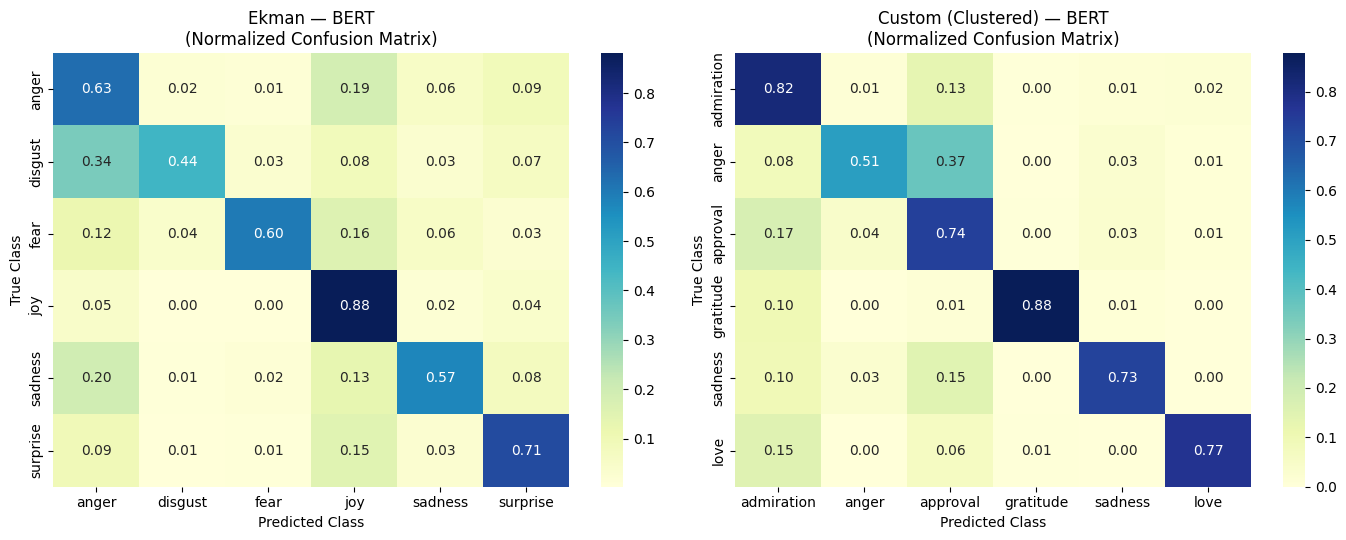


                       COMPARATIVE MODEL ANALYSIS: ELECTRA
▶ Support vs. F1 Spearman Correlation:
   • Ekman:  0.7714 (p-value = 0.0724)
   • Custom: 0.0857 (p-value = 0.8717)

▶ Performance Breakdown by Text Length Quantile:


,Length Bin,Sample Count,Avg Word Count,Macro F1
0,Short,2583,5.900000,0.707900
1,Medium,2480,13.000000,0.651800
2,Long,2319,21.000000,0.574000
,Length Bin,Sample Count,Avg Word Count,Macro F1
0,Short,2583,5.900000,0.782700
1,Medium,2480,13.000000,0.749500
2,Long,2319,21.000000,0.687500


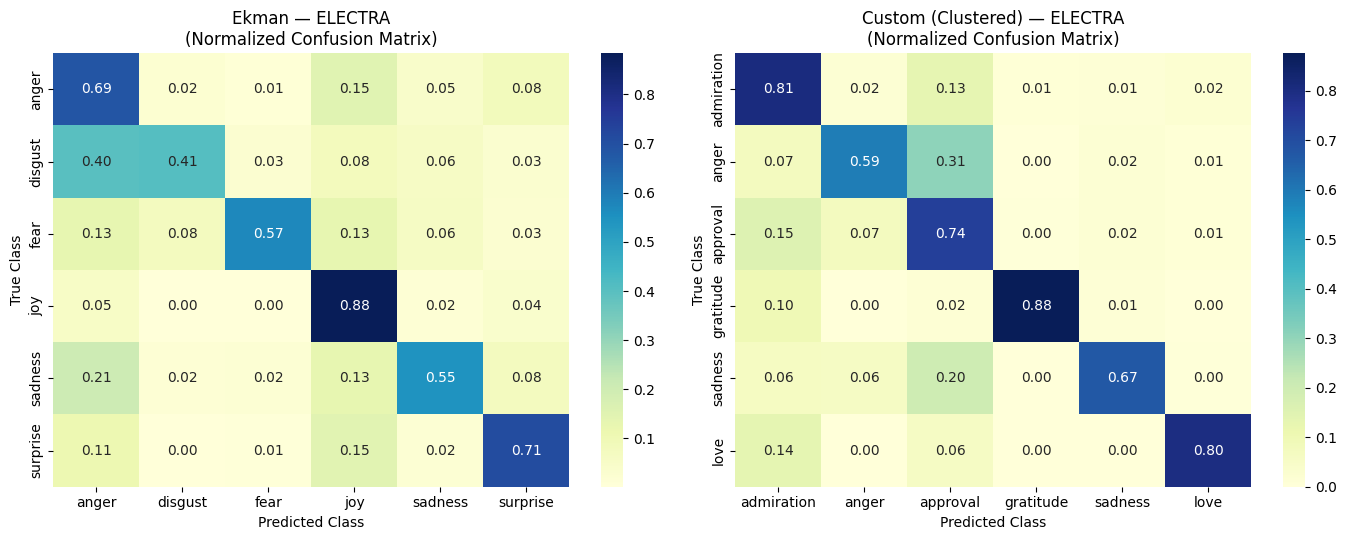


                       COMPARATIVE MODEL ANALYSIS: ROBERTA
▶ Support vs. F1 Spearman Correlation:
   • Ekman:  0.7714 (p-value = 0.0724)
   • Custom: 0.0857 (p-value = 0.8717)

▶ Performance Breakdown by Text Length Quantile:


,Length Bin,Sample Count,Avg Word Count,Macro F1
0,Short,2583,5.900000,0.702800
1,Medium,2480,13.000000,0.659900
2,Long,2319,21.000000,0.600200
,Length Bin,Sample Count,Avg Word Count,Macro F1
0,Short,2583,5.900000,0.792900
1,Medium,2480,13.000000,0.751300
2,Long,2319,21.000000,0.700000


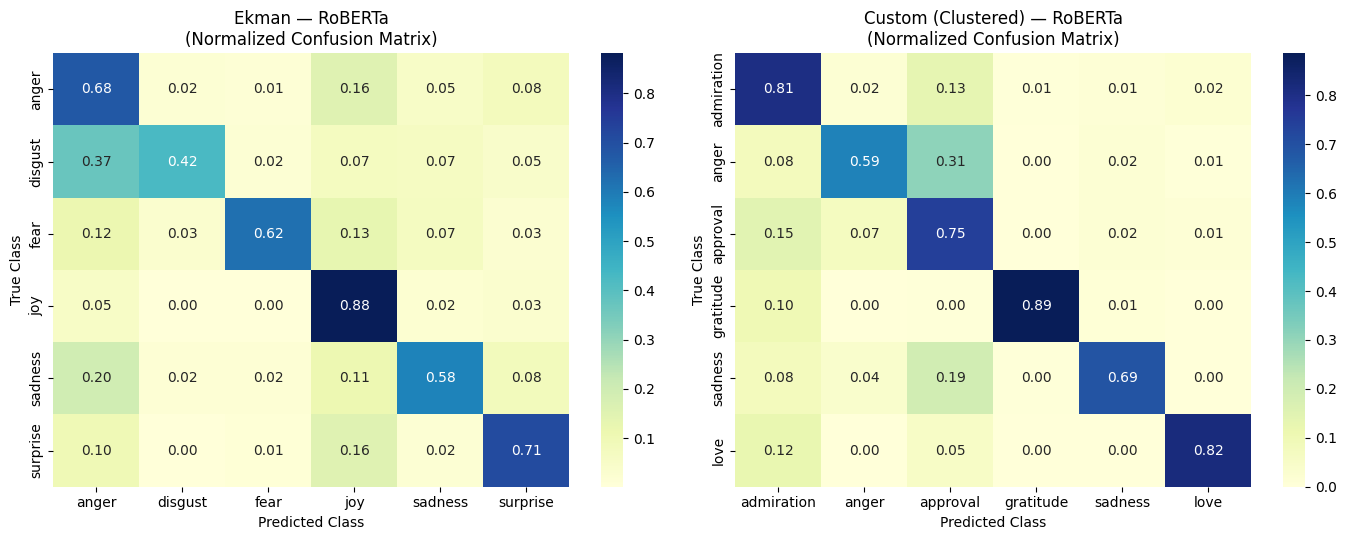

In [44]:
# description of schemes_analysis
schemes_analysis = {
    'Ekman': {
        'labels': ekman_labels,
        'texts': texts_val_ekman,
        'true_labels': true_labels_ekman,
        'preds': all_model_preds_ekman,
        'reports': all_model_reports_ekman,
    },
    'Custom (Clustered)': {
        'labels': target_labels,
        'texts': texts_val_custom,
        'true_labels': true_labels_custom,
        'preds': all_model_preds_custom,
        'reports': all_model_reports_custom,
    },
}

# Assuming model names match in both schemes
model_names = list(all_model_preds_ekman.keys())

for model_name in model_names:
    print(f"\n=========================================================================================")
    print(f"                       COMPARATIVE MODEL ANALYSIS: {model_name.upper()}")
    print(f"=========================================================================================")

    # ------------------------------------------------------------------
    # 1. Support vs F1 Spearman Correlation & Text Length Tables (Side by Side)
    # ------------------------------------------------------------------
    length_dfs = {}
    correlations = {}

    for scheme_name, scheme_data in schemes_analysis.items():
        label_names = scheme_data['labels']
        true_labels_s = np.array(scheme_data['true_labels'])
        pred_labels_s = scheme_data['preds'][model_name]
        texts_s = scheme_data['texts']
        report_df = scheme_data['reports'][model_name]

        # 1. Correlation
        corr_sf, pval_sf = spearmanr(report_df['support'], report_df['f1'])
        correlations[scheme_name] = (corr_sf, pval_sf)

        # 2. Length Stratification
        val_lengths = np.array([len(t.split()) for t in texts_s])
        length_bins = pd.qcut(val_lengths, q=3, labels=['short', 'medium', 'long'], duplicates='drop')

        length_rows = []
        for bin_name in ['short', 'medium', 'long']:
            mask = (length_bins == bin_name)
            if mask.sum() == 0:
                continue

            p_bin, r_bin, f1_bin, _ = precision_recall_fscore_support(
                true_labels_s[mask],
                pred_labels_s[mask],
                average='macro',
                zero_division=0
            )
            length_rows.append({
                'Length Bin': bin_name.capitalize(),
                'Sample Count': int(mask.sum()),
                'Avg Word Count': round(val_lengths[mask].mean(), 1),
                'Macro F1': round(f1_bin, 4)
            })

        length_dfs[scheme_name] = pd.DataFrame(length_rows)

    # Print Correlations
    print(f"▶ Support vs. F1 Spearman Correlation:")
    print(f"   • Ekman:  {correlations['Ekman'][0]:.4f} (p-value = {correlations['Ekman'][1]:.4f})")
    print(f"   • Custom: {correlations['Custom (Clustered)'][0]:.4f} (p-value = {correlations['Custom (Clustered)'][1]:.4f})")
    print("\n▶ Performance Breakdown by Text Length Quantile:")

    # Render Tables Side-by-Side in Jupyter Output
    html_ekman = length_dfs['Ekman'].style.set_table_attributes("style='display:inline'").set_caption("<b>Ekman Scheme</b>")._repr_html_()
    html_custom = length_dfs['Custom (Clustered)'].style.set_table_attributes("style='display:inline; margin-left: 30px;'").set_caption("<b>Custom Scheme</b>")._repr_html_()
    display_html(html_ekman + html_custom, raw=True)

    # ------------------------------------------------------------------
    # 2. Side-by-Side Normalized Confusion Matrices
    # ------------------------------------------------------------------
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

    for idx, (scheme_name, scheme_data) in enumerate(schemes_analysis.items()):
        label_names = scheme_data['labels']
        true_labels_s = np.array(scheme_data['true_labels'])
        pred_labels_s = scheme_data['preds'][model_name]

        conf_norm = confusion_matrix(
            true_labels_s,
            pred_labels_s,
            labels=list(range(len(label_names))),
            normalize='true'
        )
        confusion_df = pd.DataFrame(conf_norm, index=label_names, columns=label_names)

        sns.heatmap(confusion_df, annot=True, fmt='.2f', cmap='YlGnBu', cbar=True, ax=axes[idx])
        axes[idx].set_title(f'{scheme_name} — {model_name}\n(Normalized Confusion Matrix)', fontsize=12)
        axes[idx].set_ylabel('True Class')
        axes[idx].set_xlabel('Predicted Class')

    plt.tight_layout()
    plt.show()

In [45]:
import os, json, glob, shutil
from google.colab import files

# ---- 0. Local export folder (ephemeral, gets deleted when runtime resets) ----
EXPORT_PATH = "/content/GoEmotions_Artifacts"
os.makedirs(f"{EXPORT_PATH}/visuals", exist_ok=True)
os.makedirs(f"{EXPORT_PATH}/models", exist_ok=True)

# ---- 1. EDA visuals ----
df[emotion_cols].sum().sort_values(ascending=False).to_csv(
    f"{EXPORT_PATH}/visuals/emotion_counts.csv", header=["count"]
)
df[emotion_cols].corr().to_csv(f"{EXPORT_PATH}/visuals/correlation_matrix.csv")

# ---- 2. Clustering ----
df_text_sim.to_csv(f"{EXPORT_PATH}/visuals/text_similarity_matrix.csv")
with open(f"{EXPORT_PATH}/visuals/cluster_scheme.json", "w") as fh:
    json.dump({
        "clusters": text_hac_clusters,
        "representatives": {k: v["Representative"] for k, v in cluster_representatives.items()},
    }, fh, indent=2)
df_custom[custom_label_cols].sum().sort_values(ascending=False).to_csv(
    f"{EXPORT_PATH}/visuals/custom_label_distribution.csv", header=["count"]
)

# ---- 3. Label sets ----
with open(f"{EXPORT_PATH}/ekman_labels.json", "w") as fh:
    json.dump(ekman_labels, fh, indent=2)
with open(f"{EXPORT_PATH}/custom_labels.json", "w") as fh:
    json.dump(target_labels, fh, indent=2)

# ---- 4. Results summaries + per-label reports ----
df_results.to_csv(f"{EXPORT_PATH}/visuals/ekman_results_summary.csv", index=False)
df_results_custom.to_csv(f"{EXPORT_PATH}/visuals/custom_results_summary.csv", index=False)

for model_name, report_df in all_model_reports_ekman.items():
    report_df.to_csv(f"{EXPORT_PATH}/visuals/ekman_per_label_{model_name.lower()}.csv", index=False)
for model_name, report_df in all_model_reports_custom.items():
    report_df.to_csv(f"{EXPORT_PATH}/visuals/custom_per_label_{model_name.lower()}.csv", index=False)

# ---- 5. Confusion matrices ----
schemes_for_export = {
    "ekman":  {"labels": ekman_labels,  "true": np.array(true_labels_ekman),  "preds": all_model_preds_ekman},
    "custom": {"labels": target_labels, "true": np.array(true_labels_custom), "preds": all_model_preds_custom},
}
for scheme_slug, sd in schemes_for_export.items():
    for model_name, pred_labels in sd["preds"].items():
        conf_norm = confusion_matrix(
            sd["true"], pred_labels, labels=list(range(len(sd["labels"]))), normalize="true"
        )
        pd.DataFrame(conf_norm, index=sd["labels"], columns=sd["labels"]).to_csv(
            f"{EXPORT_PATH}/visuals/confusion_{scheme_slug}_{model_name.lower()}.csv"
        )

# ---- 6. RoBERTa checkpoints ----
checkpoint_map = {
    ("ekman", "roberta"):  "results_roberta",
    ("custom", "roberta"): "results_custom_roberta",
}
for (scheme_slug, arch), result_dir in checkpoint_map.items():
    ckpt_dirs = sorted(glob.glob(os.path.join(result_dir, "checkpoint-*")))
    if not ckpt_dirs:
        print(f"No checkpoint found in {result_dir}/ -- skipping {scheme_slug}/{arch}")
        continue
    best_ckpt = ckpt_dirs[-1]

    dest = f"{EXPORT_PATH}/models/{scheme_slug}/{arch}"
    os.makedirs(dest, exist_ok=True)
    for fname in os.listdir(best_ckpt):
        shutil.copy(os.path.join(best_ckpt, fname), dest)
    AutoTokenizer.from_pretrained("roberta-base").save_pretrained(dest)
    print(f"OK: Saved {scheme_slug}/{arch}")

# ---- 7. Zip it and trigger browser download ----
shutil.make_archive("/content/GoEmotions_Artifacts", "zip", EXPORT_PATH)
files.download("/content/GoEmotions_Artifacts.zip")

print("\nZipped and download triggered — check your browser downloads.")

OK: Saved ekman/roberta
OK: Saved custom/roberta


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Zipped and download triggered — check your browser downloads.
